# 04 Core analysis
RFM, cohorts, delivery vs review (Mann-Whitney U with effect size), state logistics, payments and the impact model. Every value printed here is also in `reports/facts.json`.

In [1]:
import json, pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160)
facts = json.load(open("reports/facts.json", encoding="utf-8"))
a = facts["analysis"]
from src import analysis
f = analysis.run()

analysis: revenue R$13,449,530, repeat 3.03%, late review 2.27 vs 4.29, impact R$274,689/yr


## Q3 RFM segments

In [2]:
pd.DataFrame(f['rfm']['segments']).T.sort_values('revenue', ascending=False)

,customers,customer_share,revenue,revenue_share,avg_revenue,avg_recency_days
Promising,14682.0,0.155032,3934361.32,0.292528,267.971756,94.528266
At-Risk,14097.0,0.148855,3723194.01,0.276827,264.112507,270.244662
Lost,18487.0,0.195210,2560725.65,0.190395,138.514938,473.075404
Hibernating,22590.0,0.238535,1262090.52,0.093839,55.869434,270.578840
New Customers,21973.0,0.232020,1222033.46,0.090861,55.615231,92.348155
Loyal,1649.0,0.017412,416296.54,0.030952,252.453936,322.506367
Champions,1225.0,0.012935,330828.18,0.024598,270.063820,91.059592


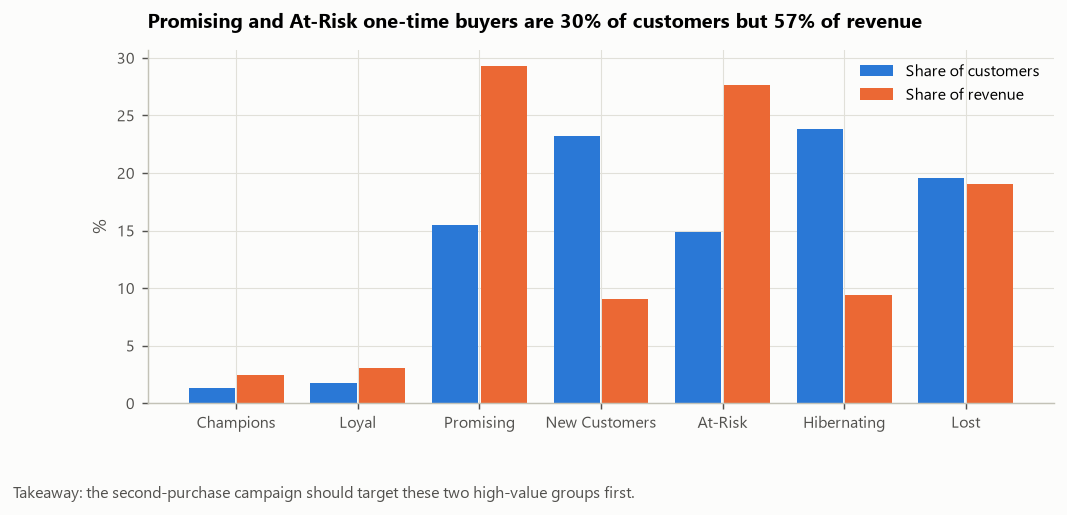

In [3]:
display(Image(filename='reports/figures/07_rfm_segments.png'))

## Q4 Cohort retention

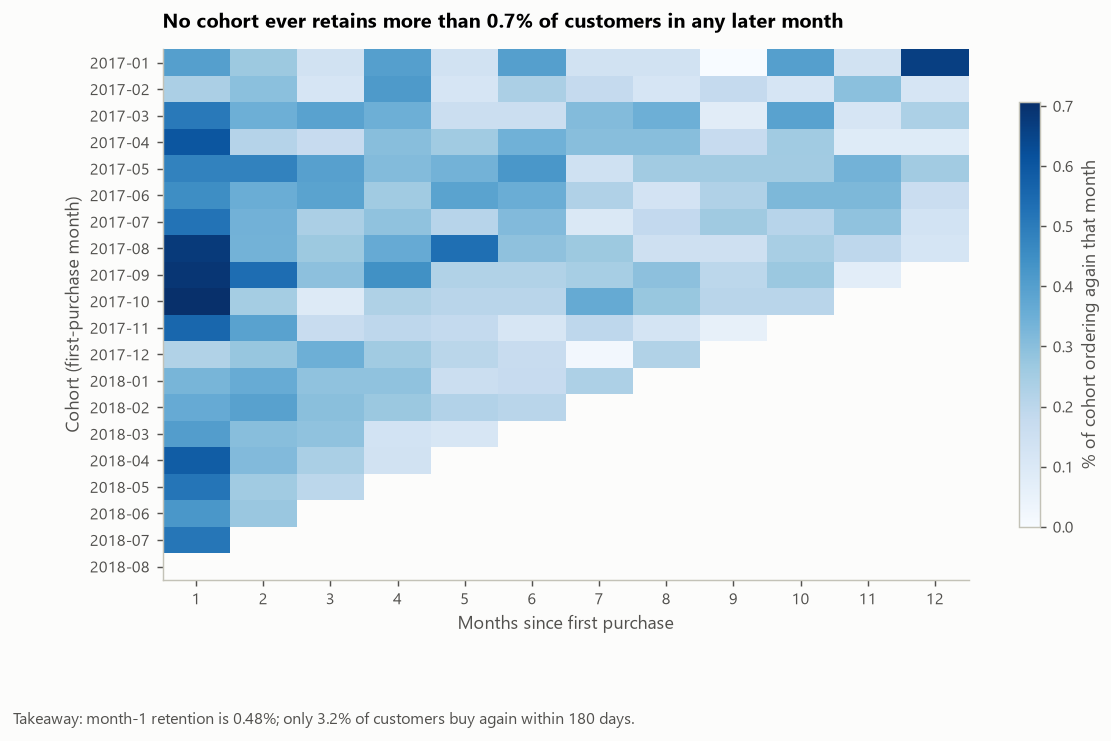

month1_retention                   0.004825
repeat_within_180d                 0.031719
eligible_customers_180d        56338.000000
repeat_orders                   3202.000000
repeat_revenue_share               0.029197
avg_repeat_order_revenue         122.638798
max_cell_retention_after_m0        0.007058
dtype: float64

In [4]:
display(Image(filename='reports/figures/08_cohort_heatmap.png'))
pd.Series(f['cohort'])

## Q5 Late delivery vs review score
Two-sided Mann-Whitney U on review scores of late vs on-time delivered orders. Rank-biserial correlation as effect size; Welch interval for the mean gap.

In [5]:
pd.Series(f['delivery'])

late_avg_review            2.270618e+00
ontime_avg_review          4.291157e+00
review_gap                 2.020540e+00
review_gap_ci_low          1.981249e+00
review_gap_ci_high         2.059830e+00
n_late_reviewed            6.378000e+03
n_ontime_reviewed          8.918200e+04
n_reviewed                 9.556000e+04
mwu_u                      1.029010e+08
mwu_p_value                0.000000e+00
rank_biserial             -6.381839e-01
late_low_review_share      6.241769e-01
ontime_low_review_share    9.247382e-02
late8_avg_review           1.696653e+00
late8_low_review_share     7.927312e-01
late8_orders               2.779000e+03
dtype: float64

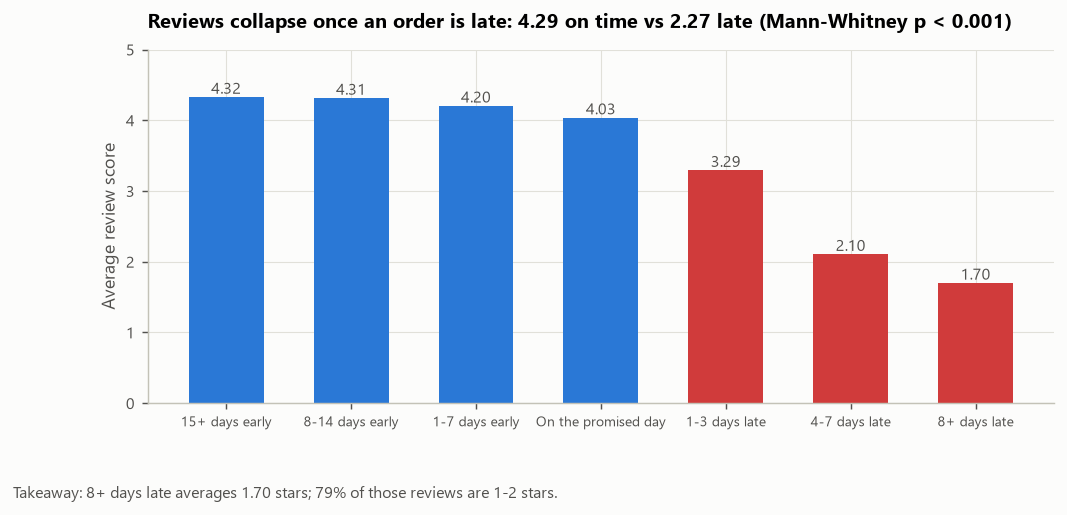

repeat_rate_ontime_first        0.030590
repeat_rate_late_first          0.025374
n_ontime_first              86695.000000
n_late_first                 6345.000000
gap_pp                          0.521569
z                               2.342104
p_value                         0.019175
dtype: float64

In [6]:
display(Image(filename='reports/figures/09_delay_vs_review.png'))
pd.Series(f['retention_vs_delivery'])

## Q6 States and Q7 payments

In [7]:
pd.DataFrame(f['state']['worst5'])

,state,late_rate,delivered_orders,avg_delivery_days,avg_review
0,AL,0.214646,396.0,24.522339,3.847328
1,MA,0.175316,713.0,21.535557,3.829337
2,SE,0.153614,332.0,21.438612,3.900302
3,PI,0.138947,475.0,19.440832,3.993617
4,CE,0.138256,1273.0,21.238458,3.940016


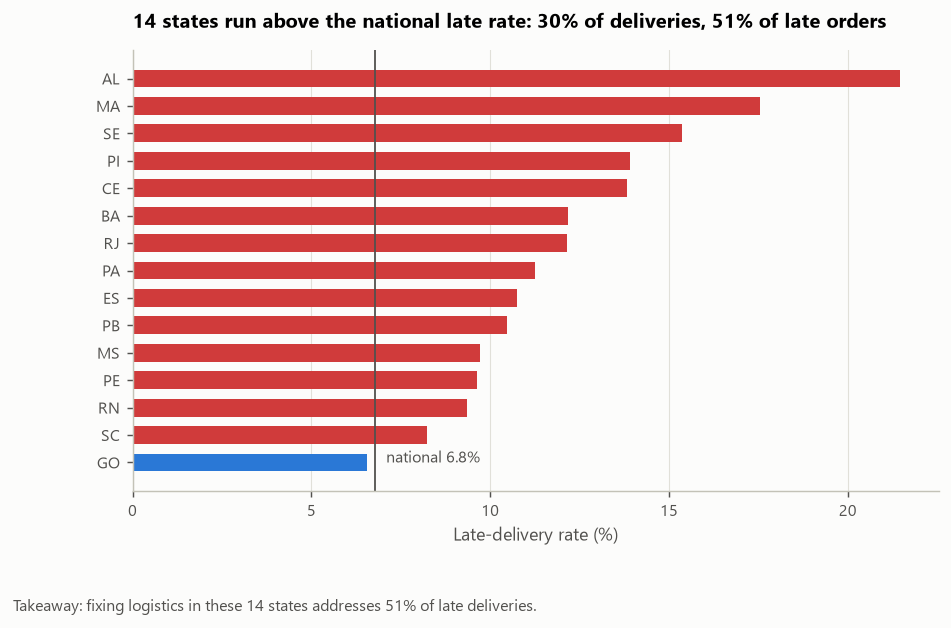

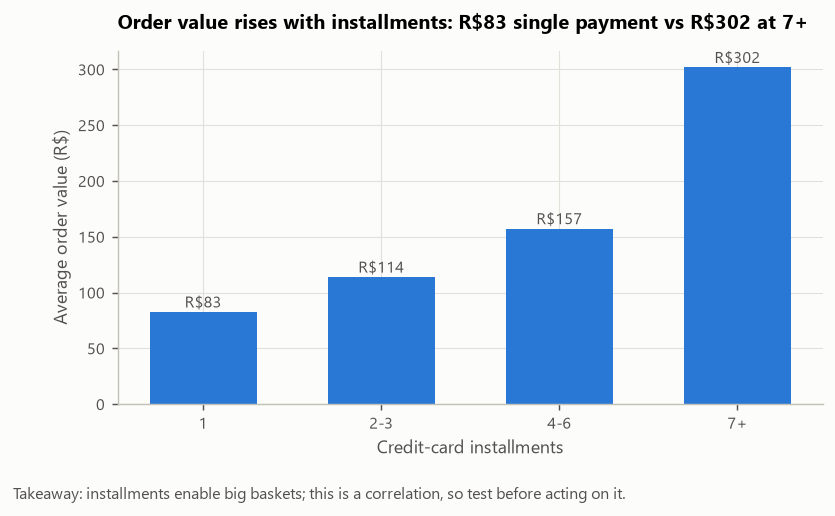

credit_card_share                0.754691
boleto_share                     0.198938
voucher_share                    0.030928
debit_card_share                 0.015444
aov_credit_card                143.614256
aov_boleto                     121.677830
cc_avg_installments              3.549954
aov_single_payment              82.622733
aov_7plus_installments         301.787235
share_cc_7plus                   0.161704
spearman_installments_value      0.449048
dtype: float64

In [8]:
display(Image(filename='reports/figures/10_state_late_rate.png'))
display(Image(filename='reports/figures/11_installments_aov.png'))
pd.Series(f['payment'])

## Impact model
Assumptions are inputs; change them in `src/analysis.py` (or in the Excel *Impact model* sheet).

In [9]:
pd.Series(f['assumptions']), pd.Series(f['impact'])

(repeat_lift_pp                  1.000
 repeat_lift_low_pp              0.500
 repeat_lift_high_pp             2.000
 basket_lift_pp                  2.000
 min_state_orders              300.000
 ci_level_pct                   95.000
 alpha                           0.050
 p_floor                         0.001
 repeat_window_days            180.000
 top_n_chart                    15.000
 dashboard_min_state_orders    100.000
 months_per_year                12.000
 dtype: float64,
 annual_new_customers         77509.440000
 avg_repeat_order_revenue       122.638798
 a1_repeat_revenue            95056.645263
 a1_per_pp                    95056.645263
 a1_low                       47528.322632
 a1_high                     190113.290526
 a2_late_orders_avoided        1477.282164
 a2_target_late_rate_2018         0.134405
 a2_review_uplift                 0.037705
 a2_repeat_revenue              944.937362
 a3_multi_item_share              0.099362
 a3_avg_addon_revenue           111.269590